In [121]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

wti = pd.read_csv("wti-daily.csv")
wti["Date"] = pd.to_datetime(wti["Date"])
wti = wti.set_index("Date")
wti

,Price
Date,
1986-01-02,25.56
1986-01-03,26.00
1986-01-06,26.53
1986-01-07,25.85
1986-01-08,25.87
...,...
2025-10-21,58.66
2025-10-22,59.30
2025-10-23,62.44


In [122]:
brent = pd.read_csv("brent-daily.csv")
brent["Date"] = pd.to_datetime(brent["Date"])
brent = brent.set_index("Date")
brent

,Price
Date,
1987-05-20,18.63
1987-05-21,18.45
1987-05-22,18.55
1987-05-25,18.60
1987-05-26,18.63
...,...
2025-10-21,61.00
2025-10-22,62.28
2025-10-23,66.32


Q1. Plot the average price trend of oil from 1992-2002

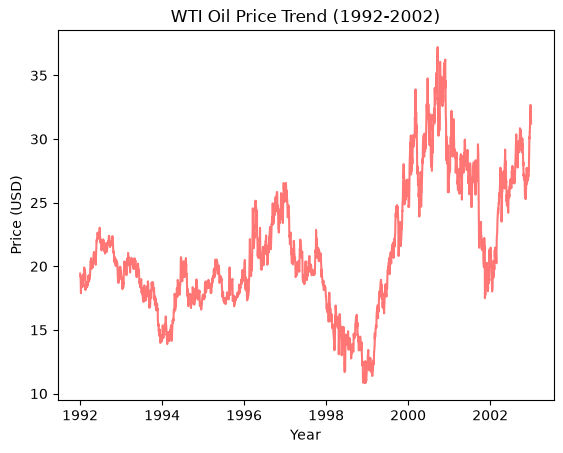

In [123]:
colors = ["#ff7675", "#fab1a0", "#ffeaa7", "#55efc4", "#74b9ff"]

wti_f = wti[(wti.index >= "1992-01-01") & (wti.index <= "2002-12-31")]
plt.plot(wti_f, label="WTI", color=colors[0])

plt.title("WTI Oil Price Trend (1992-2002)")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.show()

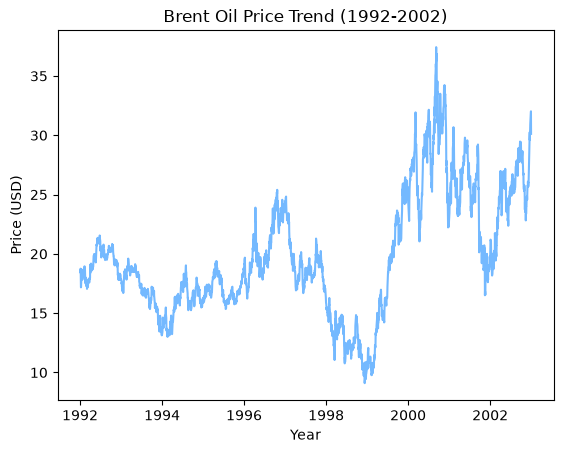

In [124]:
brent_f = brent[(brent.index >= "1992-01-01") & (brent.index <= "2002-12-31")]

plt.plot(brent_f, label="Brent", color=colors[-1])
plt.title("Brent Oil Price Trend (1992-2002)")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.show()

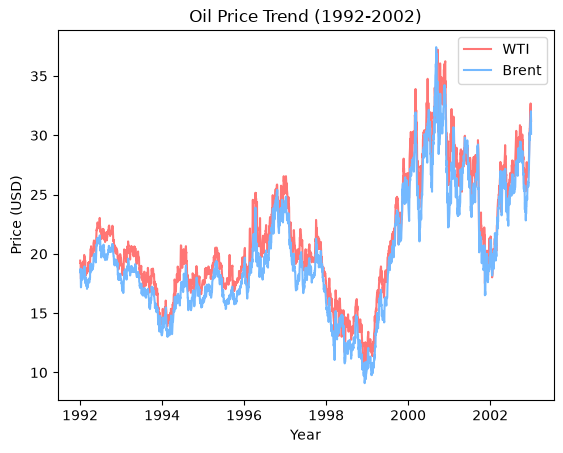

In [125]:
# plot both
plt.plot(wti_f, label="WTI", color=colors[0])
plt.plot(brent_f, label="Brent", color=colors[-1])

plt.title("Oil Price Trend (1992-2002)")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.legend()
plt.show()

In [126]:
# join both datasets on the index (Date)
oil_prices = pd.merge(
  wti_f, brent_f, left_index=True, right_index=True, suffixes=("_WTI", "_Brent")
)
# add diference
oil_prices["Difference"] = np.abs(oil_prices["Price_WTI"] - oil_prices["Price_Brent"])
oil_prices

,Price_WTI,Price_Brent,Difference
Date,,,
1992-01-02,19.43,18.45,0.98
1992-01-03,19.22,18.50,0.72
1992-01-06,19.24,18.75,0.49
1992-01-07,18.72,18.40,0.32
1992-01-08,17.95,17.30,0.65
...,...,...,...
2002-12-23,32.09,30.61,1.48
2002-12-24,32.13,30.93,1.20
2002-12-27,32.68,31.49,1.19


some dates are not in both datasets. for the sake of simplicitly we are discarding those.

,Price_WTI,Price_Brent,Difference
Date,,,
2001-01-19,32.12,26.29,5.83
2001-01-18,30.42,24.74,5.68
2001-01-17,29.77,24.27,5.50
2000-12-19,29.34,24.36,4.98
1996-04-17,24.67,19.88,4.79
...,...,...,...
1999-10-08,20.81,20.78,0.03
2002-04-23,26.28,26.26,0.02
2002-01-14,18.88,18.89,0.01


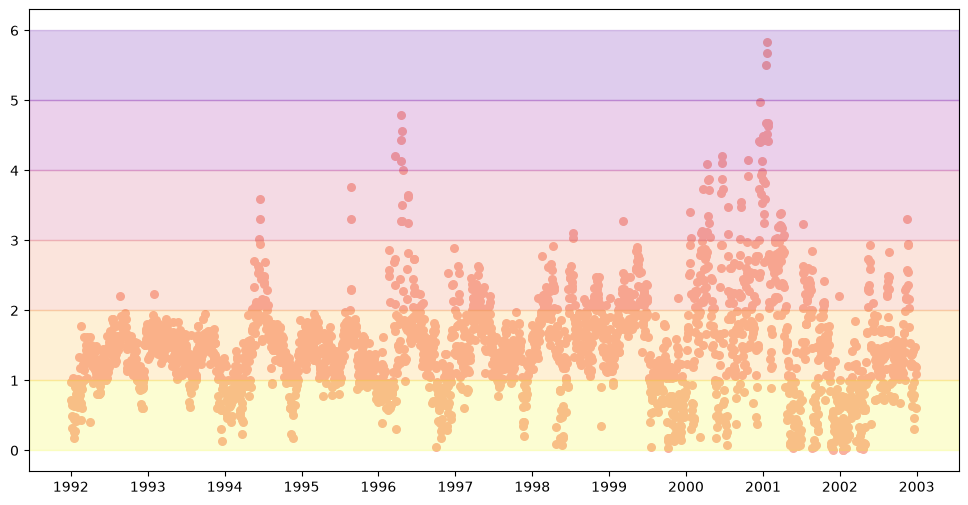

In [127]:
plt.figure(figsize=(12, 6))
plt.scatter(
  oil_prices.index, oil_prices["Difference"], label="Difference", color=colors[1], s=30
)

# highlight background with color gradient, with plasma
for i in range(6):
  plt.axhspan(i, i + 1, alpha=0.2, color=plt.cm.plasma(1 - i / 6))

plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

oil_prices.sort_values(by="Difference", ascending=False)

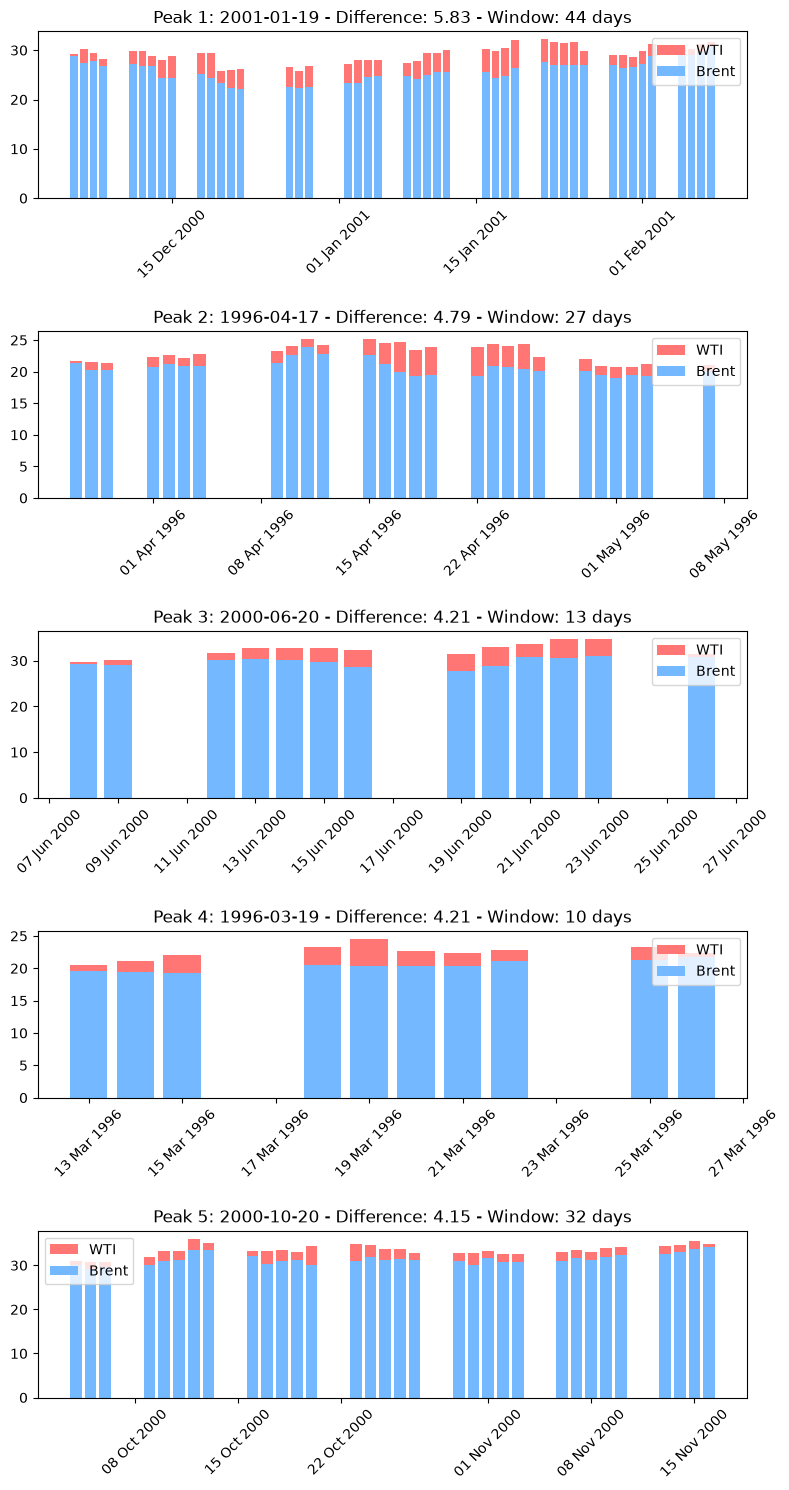

In [ ]:
def get_window(peak_date, until_less_than=1):
  peak_pos = oil_prices.index.get_loc(peak_date)
  left = right = peak_pos

  while left > 0 and oil_prices.iloc[left - 1]["Difference"] >= until_less_than:
    left -= 1

  while (
    right < len(oil_prices) - 1
    and oil_prices.iloc[right + 1]["Difference"] >= until_less_than
  ):
    right += 1

  # Include one observation below the threshold on each side
  left = max(0, left - 1)
  right = min(len(oil_prices) - 1, right + 1)

  return oil_prices.iloc[left : right + 1]


def get_highest_all(n):
  checked_peaks = set()
  # sort
  sorted_peaks = oil_prices.sort_values(by="Difference", ascending=False)
  # get the highest peaks
  iterrows = sorted_peaks.iterrows()
  i = 0
  while i != n:
    peak_date, peak = next(iterrows)
    if peak_date in checked_peaks:
      continue
    [checked_peaks.add(date) for date in get_window(peak_date).index]
    i += 1
    if peak["Difference"] < 1:
      break
    yield peak, get_window(peak_date)


fig, axes = plt.subplots(5, 1, figsize=(8, 15))

for i, (peak, window) in enumerate(get_highest_all(5)):
  axes[i].bar(window.index, window["Price_WTI"], label="WTI", color=colors[0])
  axes[i].bar(window.index, window["Price_Brent"], label="Brent", color=colors[-1])

  axes[i].xaxis.set_major_locator(mdates.AutoDateLocator())
  axes[i].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
  axes[i].tick_params(axis="x", rotation=45)

  axes[i].set_title(
    f"Peak {i + 1}: {peak.name.date()} - "
    f"Difference: {peak['Difference']:.2f} - "
    f"Window: {len(window)} days"
  )
  axes[i].legend()

plt.tight_layout(h_pad=2.0)
plt.show()

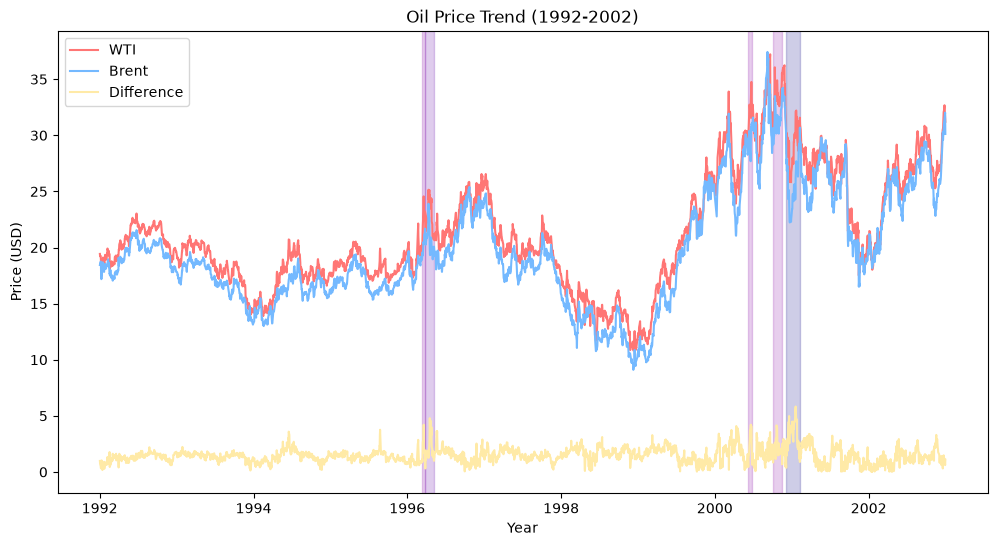

In [129]:
fig, ax = plt.subplots(figsize=(12, 6))
plt.plot(oil_prices.index, oil_prices["Price_WTI"], label="WTI", color=colors[0])
plt.plot(oil_prices.index, oil_prices["Price_Brent"], label="Brent", color=colors[-1])
plt.plot(
  oil_prices.index, oil_prices["Difference"], label="Difference", color=colors[2]
)

# highlight 5 highest peaks
for peak, window in get_highest_all(5):
  ax.axvspan(
    window.index[0],
    window.index[-1],
    alpha=0.2,
    color=plt.cm.plasma(1 - peak["Difference"] / oil_prices["Difference"].max()),
  )

plt.title("Oil Price Trend (1992-2002)")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.legend()
plt.show()

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sales = pd.read_excel("sales.xlsx")
sales

,Invoice ID,Branch,City,Customer type,Gender,Product Code,Unit price,Quantity,Tax 5%,Total,Date,Payment,COGS,gross margin percentage,gross income,Rating
0,123-19-1176,A,Yangon,Member,Male,1,58.22,8,23.2880,489.0480,2019-01-27,Ewallet,465.76,4.761905,23.2880,8.4
1,699-14-3026,C,Naypyitaw,Normal,Male,1,85.39,7,29.8865,627.6165,2019-03-25,Ewallet,597.73,4.761905,29.8865,4.1
2,355-53-5943,A,Yangon,Member,Female,1,68.84,6,20.6520,433.6920,2019-02-25,Ewallet,413.04,4.761905,20.6520,5.8
3,315-22-5665,C,Naypyitaw,Normal,Female,1,73.56,10,36.7800,772.3800,2019-02-24,Ewallet,735.60,4.761905,36.7800,8.0
4,692-92-5582,B,Mandalay,Member,Female,1,54.84,3,8.2260,172.7460,2019-02-20,Credit card,164.52,4.761905,8.2260,5.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,374-38-5555,B,Mandalay,Normal,Female,3,63.71,5,15.9275,334.4775,2019-02-07,Ewallet,318.55,4.761905,15.9275,8.5
996,552-44-5977,B,Mandalay,Member,Male,3,62.00,8,24.8000,520.8000,2019-01-03,Credit card,496.00,4.761905,24.8000,6.2
997,745-74-0715,A,Yangon,Normal,Male,3,58.03,2,5.8030,121.8630,2019-03-10,Ewallet,116.06,4.761905,5.8030,8.8
998,303-96-2227,B,Mandalay,Normal,Female,3,97.38,10,48.6900,1022.4900,2019-03-02,Ewallet,973.80,4.761905,48.6900,4.4


In [5]:
sales.dtypes

Invoice ID                            str
Branch                                str
City                                  str
Customer type                         str
Gender                                str
Product Code                        int64
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                       datetime64[us]
Payment                               str
COGS                              float64
gross margin percentage           float64
gross income                      float64
Rating                            float64
dtype: object

In [6]:
from skimpy import skim

skim(sales)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                  Data Types                                                               │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━━━━┳━━━━━━━┓                                                       │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type    ┃ Count ┃                                                       │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━━━━╇━━━━━━━┩                                                       │
│ │ Number of rows    │ 1000   │ │ float64        │ 7     │                                                       │
│ │ Number of columns │ 16     │ │ string         │ 6     │                                                       │
│ └───────────────────┴────────┘ │ int64          │ 2     │                                                       │
│                                │ datetime64[us] │ 1     │                                                       │
│                                └────────────────┴───────┘                                                       │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━┓  │
│ ┃ column                    ┃ NA  ┃ NA %  ┃ mean   ┃ sd    ┃ p0     ┃ p25   ┃ p50   ┃ p75   ┃ p100  ┃ hist   ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━┩  │
│ │       Product Code        │   0 │     0 │  1.486 │ 0.615 │      1 │     1 │     1 │     2 │     3 │ ▇  ▅ ▁ │  │
│ │        Unit price         │   0 │     0 │  55.67 │ 26.49 │  10.08 │ 32.88 │ 55.23 │ 77.94 │ 99.96 │ ▇▇▇▇▇▇ │  │
│ │         Quantity          │   0 │     0 │   5.51 │ 2.923 │      1 │     3 │     5 │     8 │    10 │ ▇▃▇▃▇▇ │  │
│ │          Tax 5%           │   0 │     0 │  15.38 │ 11.71 │ 0.5085 │ 5.925 │ 12.09 │ 22.45 │ 49.65 │ ▇▆▃▂▂▁ │  │
│ │           Total           │   0 │     0 │    323 │ 245.9 │  10.68 │ 124.4 │ 253.8 │ 471.4 │  1043 │ ▇▆▃▂▂▁ │  │
│ │           COGS            │   0 │     0 │  307.6 │ 234.2 │  10.17 │ 118.5 │ 241.8 │ 448.9 │   993 │ ▇▆▃▂▂▁ │  │
│ │  gross margin percentage  │   0 │     0 │  4.762 │     0 │  4.762 │ 4.762 │ 4.762 │ 4.762 │ 4.762 │     ▇  │  │
│ │       gross income        │   0 │     0 │  15.38 │ 11.71 │ 0.5085 │ 5.925 │ 12.09 │ 22.45 │ 49.65 │ ▇▆▃▂▂▁ │  │
│ │          Rating           │   0 │     0 │  6.973 │ 1.719 │      4 │   5.5 │     7 │   8.5 │    10 │ ▇▇▇▇▇▇ │  │
│ └───────────────────────────┴─────┴───────┴────────┴───────┴────────┴───────┴───────┴───────┴───────┴────────┘  │
│                                                    datetime                                                     │
│ ┏━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓  │
│ ┃ column         ┃ NA     ┃ NA %       ┃ first                 ┃ last                  ┃ frequency           ┃  │
│ ┡━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩  │
│ │      Date      │      0 │          0 │      2019-01-01       │      2019-03-30       │         NA          │  │
│ └────────────────┴────────┴────────────┴───────────────────────┴───────────────────────┴─────────────────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┓  │
│ ┃           ┃    ┃      ┃           ┃           ┃           ┃           ┃ chars per ┃ words per ┃ total      ┃  │
│ ┃ column    ┃ NA ┃ NA % ┃ shortest  ┃ longest   ┃ min       ┃ max       ┃ row       ┃ row       ┃ words      ┃  │
│ ┡━━━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━

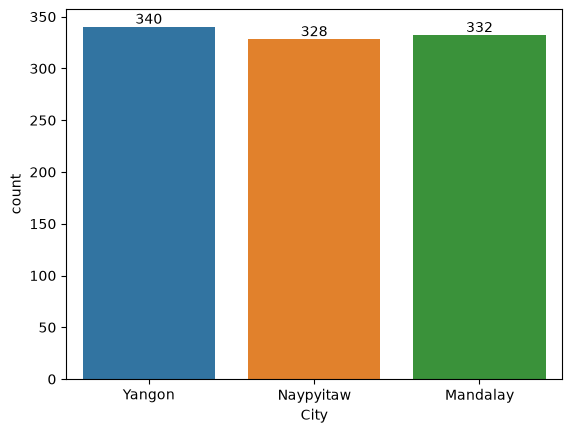

In [7]:
ax = sns.countplot(data=sales, x="City", hue="City", legend=False)

for container in ax.containers:
    ax.bar_label(container)
plt.show()

Yanhon has the majority of sales by a small margin.

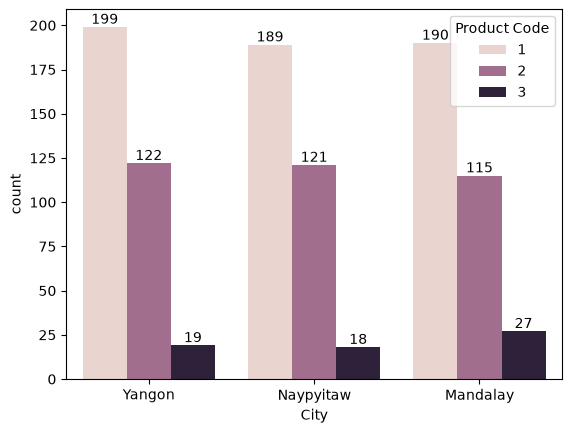

In [8]:
ax = sns.countplot(data=sales, x="City", hue="Product Code")

for container in ax.containers:
  ax.bar_label(container)
plt.show()

Similar story per product, except Mandalay has a bigger amount of sales for product 3 compared to the other cities.

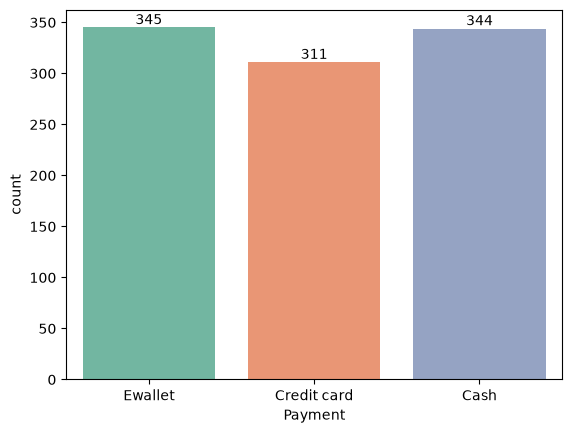

In [9]:
# for each payment
ax = sns.countplot(data=sales, x="Payment", hue="Payment", legend=False, palette="Set2")

for container in ax.containers:
  ax.bar_label(container)

Most sales are done with E-wallets and Credit cards, with ~30 sales difference compared to cash.

<Axes: xlabel='Payment', ylabel='Unit price'>

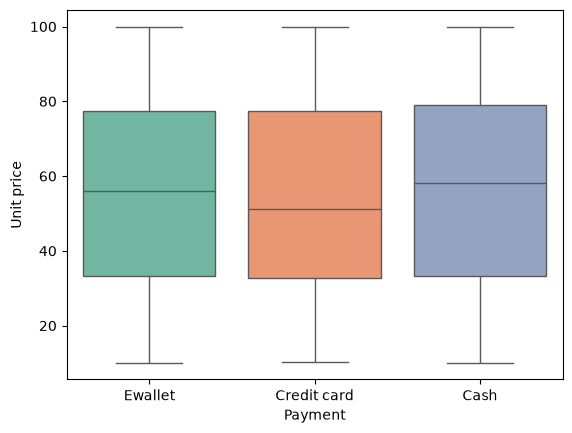

In [10]:
sns.boxplot(data=sales, x="Payment", hue="Payment", y="Unit price", palette="Set2", dodge=False)

<Axes: xlabel='Unit price', ylabel='Density'>

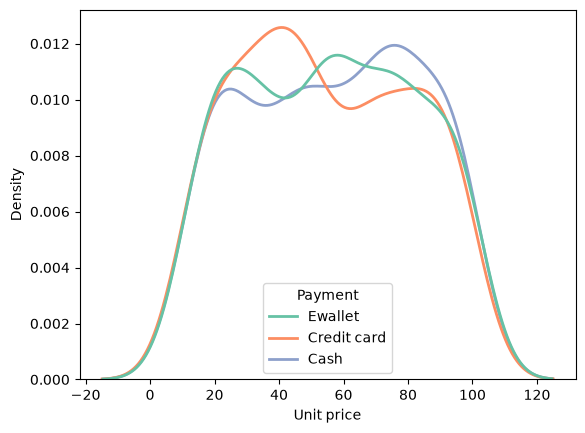

In [11]:
sns.kdeplot(
  data=sales,
  x="Unit price",
  hue="Payment",
  palette="Set2",
  common_norm=False,
  linewidth=2
)

Credit card sales are usually lower, while the higher are usually Cash.

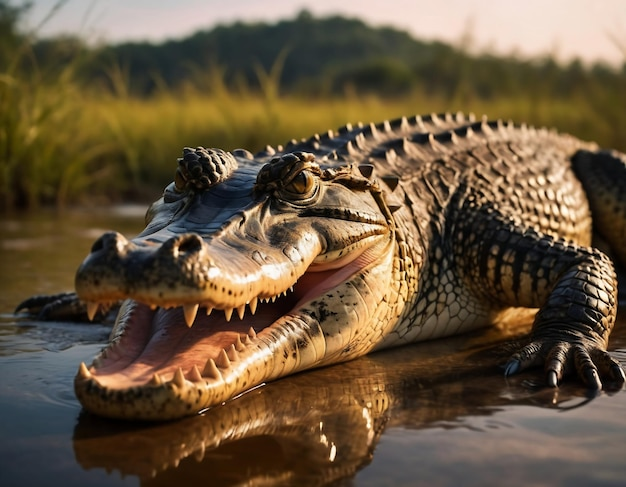

In [13]:
from PIL import Image, ImageEnhance, ImageFilter, ImageOps

crocodile = Image.open("2.jpg")
crocodile

In [14]:
import numpy as np
arr = np.mean(np.array(crocodile), axis=2)
arr

array([[101.        , 105.        , 110.        , ..., 221.66666667,
        221.66666667, 221.66666667],
       [ 96.        ,  99.        , 105.        , ..., 221.66666667,
        221.66666667, 221.66666667],
       [ 85.33333333,  89.33333333,  94.33333333, ..., 221.66666667,
        221.66666667, 221.66666667],
       ...,
       [ 36.33333333,  36.33333333,  36.33333333, ...,  70.66666667,
         70.66666667,  70.66666667],
       [ 35.33333333,  35.33333333,  36.33333333, ...,  67.66666667,
         67.66666667,  67.66666667],
       [ 35.33333333,  35.33333333,  35.33333333, ...,  65.66666667,
         65.66666667,  65.66666667]], shape=(487, 626))

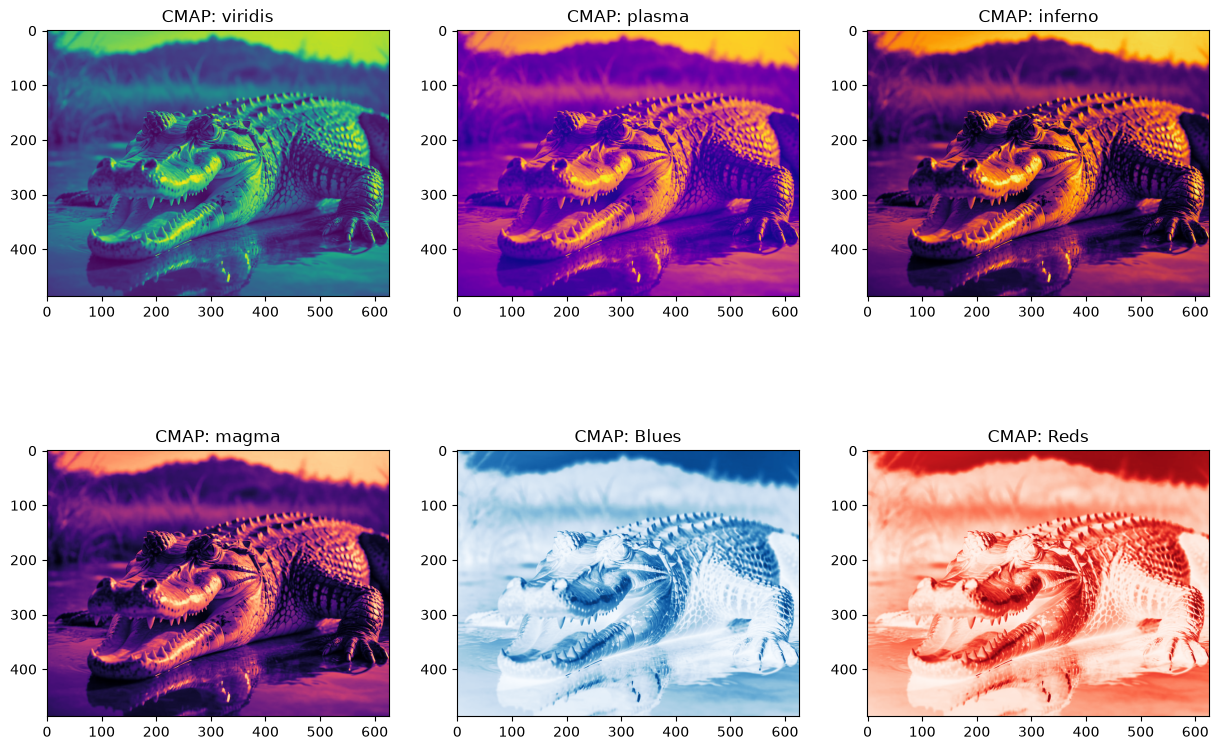

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

cmaps = ['viridis', 'plasma', 'inferno', 'magma', 'Blues', 'Reds']

for i, cmap in enumerate(cmaps):
    row = i // 3
    col = i % 3
    axs[row, col].imshow(arr, cmap=cmap)
    axs[row, col].set_title(f'CMAP: {cmap}')

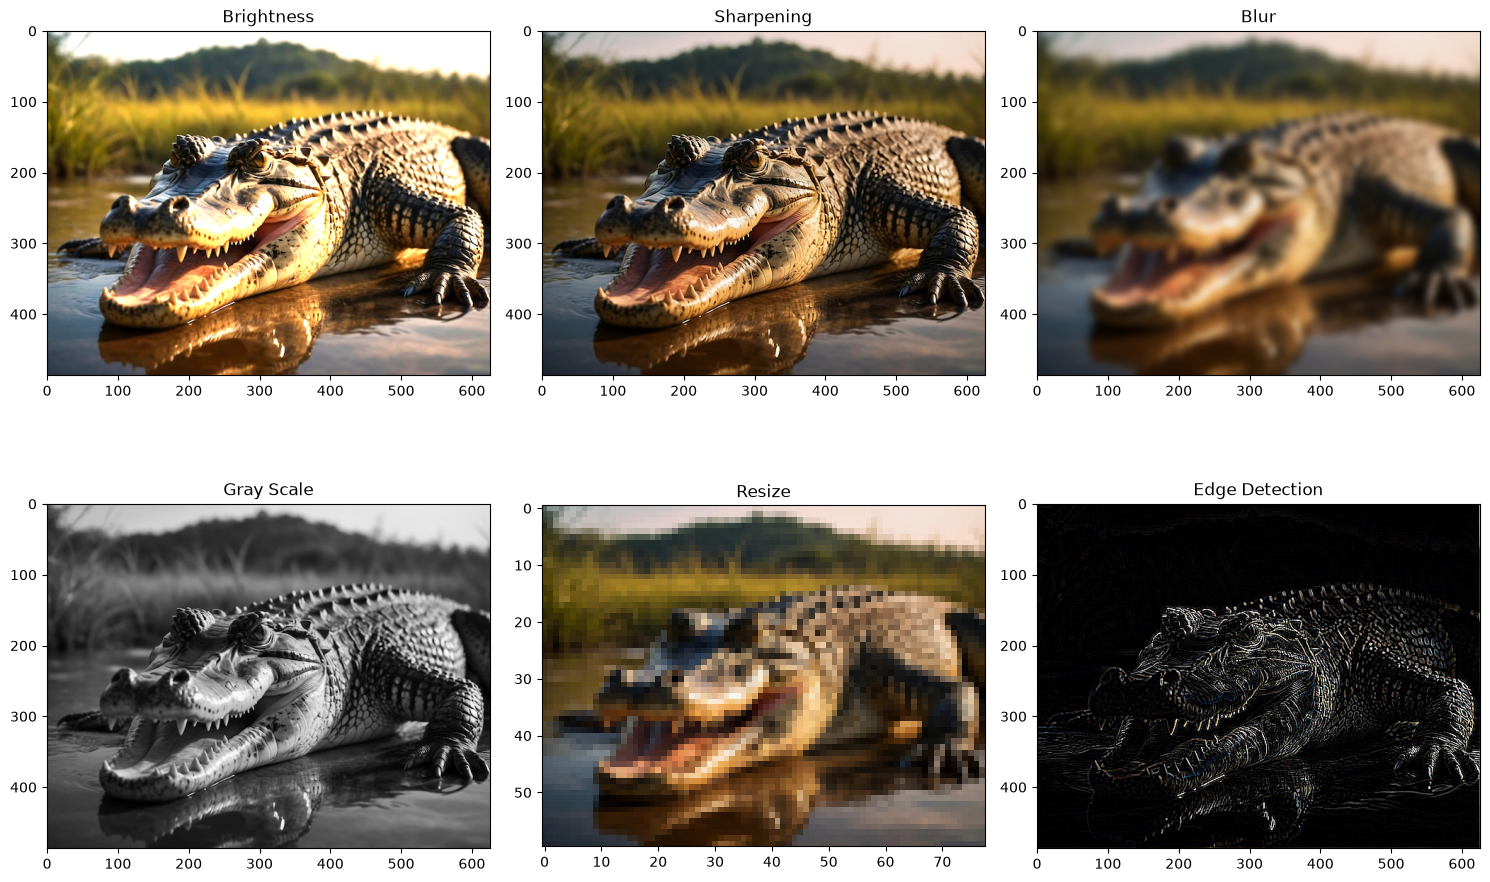

In [19]:
# apply 6 different filters with ImageEnchance and ImageFilter
fig, axs = plt.subplots(2, 3, figsize=(15, 10))


# brightness
enhancer = ImageEnhance.Brightness(crocodile)
brightened = enhancer.enhance(1.5)
axs[0, 0].imshow(brightened)
axs[0, 0].set_title('Brightness')

# sharpening
enhancer = ImageEnhance.Sharpness(crocodile)
sharpened = enhancer.enhance(2.0)
axs[0, 1].imshow(sharpened)
axs[0, 1].set_title('Sharpening')

# blur
blurred = crocodile.filter(ImageFilter.GaussianBlur(radius=5))
axs[0, 2].imshow(blurred)
axs[0, 2].set_title('Blur')

# gray scale
grayscale = ImageOps.grayscale(crocodile)
axs[1, 0].imshow(grayscale, cmap='gray')
axs[1, 0].set_title('Gray Scale')

# resize
resized = crocodile.resize((crocodile.width // 8, crocodile.height // 8))
axs[1, 1].imshow(resized)
axs[1, 1].set_title('Resize')

# edge detection
edges = crocodile.filter(ImageFilter.FIND_EDGES)
axs[1, 2].imshow(edges)
axs[1, 2].set_title('Edge Detection')


# show plots
plt.tight_layout()
plt.show()
  